In [1]:
import mne
import matplotlib.pyplot as plt
from pathlib import Path

import pandas as pd

ROOT = Path().resolve().parent

set_file1 = ROOT / "sub-Rc01" / "ses-1" / "eeg" / "sub-Rc01_ses-1_task-SmartickDataset_run-1_eeg.set"
set_file2 = ROOT / "sub-Rc01" / "ses-1" / "eeg" / "sub-Rc01_ses-1_task-SmartickDataset_run-2_eeg.set"

raw1 = mne.io.read_raw_eeglab(set_file1, preload=True)
raw2 = mne.io.read_raw_eeglab(set_file2, preload=True)

print(raw1)
print("Channels:", len(raw1.ch_names))
print("Sampling frequency:", raw1.info["sfreq"])
print("Duration:", raw1.times[-1], "seconds")
print("Number of samples:", raw1.n_times)
print("Channel names:")
print(raw1.ch_names)

print(raw2)
print("Channels:", len(raw2.ch_names))
print("Sampling frequency:", raw2.info["sfreq"])
print("Duration:", raw2.times[-1], "seconds")
print("Number of samples:", raw2.n_times)
print("Channel names:")
print(raw2.ch_names)

<RawEEGLAB | sub-Rc01_ses-1_task-SmartickDataset_run-1_eeg.set, 32 x 46080 (180.0 s), ~11.3 MiB, data loaded>
Channels: 32
Sampling frequency: 256.0
Duration: 179.99609375 seconds
Number of samples: 46080
Channel names:
['FP1', 'FP2', 'F7', 'F3', 'Fz', 'F4', 'F8', 'FT10', 'FT9', 'T7', 'FC5', 'C3', 'FC1', 'FC2', 'FC6', 'C4', 'Cz', 'CP1', 'CP5', 'TP9', 'CP2', 'CP6', 'TP10', 'T8', 'P7', 'P3', 'Pz', 'P4', 'P8', 'O1', 'Oz', 'O2']
<RawEEGLAB | sub-Rc01_ses-1_task-SmartickDataset_run-2_eeg.set, 32 x 57439 (224.4 s), ~14.1 MiB, data loaded>
Channels: 32
Sampling frequency: 256.0
Duration: 224.3671875 seconds
Number of samples: 57439
Channel names:
['FP1', 'FP2', 'F7', 'F3', 'Fz', 'F4', 'F8', 'FT10', 'FT9', 'T7', 'FC5', 'C3', 'FC1', 'FC2', 'FC6', 'C4', 'Cz', 'CP1', 'CP5', 'TP9', 'CP2', 'CP6', 'TP10', 'T8', 'P7', 'P3', 'Pz', 'P4', 'P8', 'O1', 'Oz', 'O2']


In [2]:
data1 = raw1.get_data()
data2 = raw2.get_data()

print("Data shape:", data1.shape)
print("Data shape:", data2.shape)

Data shape: (32, 46080)
Data shape: (32, 57439)


In [3]:
# EEG preprocessing

raw_clean1 = raw1.copy()

# Band-pass filtering
raw_clean1.filter(
    l_freq=0.5,
    h_freq=50.0,
    fir_design="firwin"
)

# Notch filter for power-line interference
raw_clean1.notch_filter(freqs=50)

raw_clean2 = raw2.copy()

# Band-pass filtering
raw_clean2.filter(
    l_freq=0.5,
    h_freq=50.0,
    fir_design="firwin"
)

# Notch filter for power-line interference
raw_clean2.notch_filter(freqs=50)



print("Preprocessing completed.")
print("High-pass filter : 0.5 Hz")
print("Low-pass filter  : 50 Hz")
print("Notch filter     : 50 Hz")

Filtering raw data in 1 contiguous segment
Setting up band-pass filter from 0.5 - 50 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 0.50
- Lower transition bandwidth: 0.50 Hz (-6 dB cutoff frequency: 0.25 Hz)
- Upper passband edge: 50.00 Hz
- Upper transition bandwidth: 12.50 Hz (-6 dB cutoff frequency: 56.25 Hz)
- Filter length: 1691 samples (6.605 s)

Filtering raw data in 1 contiguous segment
Setting up band-stop filter from 49 - 51 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandstop filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 49.38
- Lower transition bandwidth: 0.50 Hz (-6 dB cutoff frequency: 49.12 Hz)
- Upper passband e

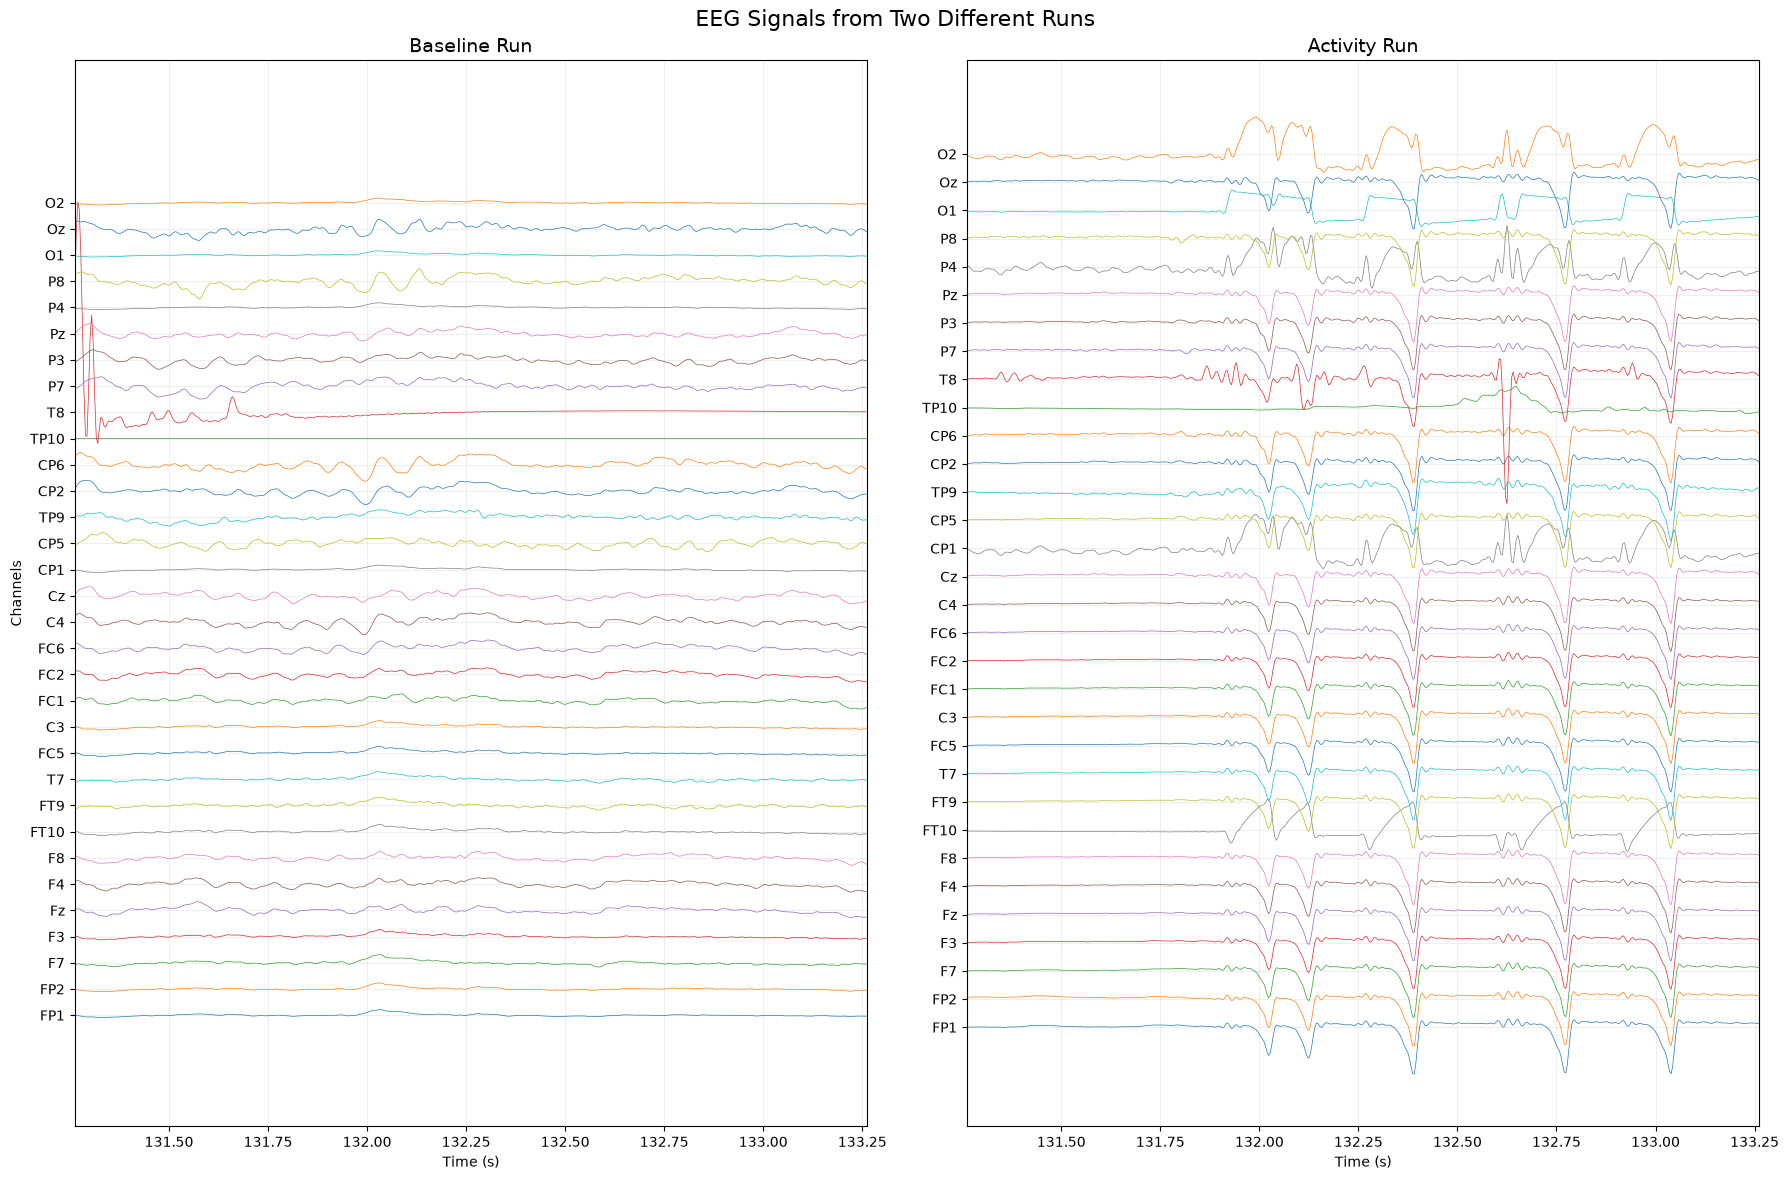

In [4]:
import numpy as np
import matplotlib.pyplot as plt

data1 = raw_clean1.get_data()
times1 = raw_clean1.times

data2 = raw_clean2.get_data()
times2 = raw_clean2.times

event_time = 131.2617188
end_time = event_time + 2

fig, axes = plt.subplots(1, 2, figsize=(18, 12))

spacing = 5

for i in range(data1.shape[0]):
    signal1 = data1[i]
    signal2 = data2[i]

    # Normalize each channel
    signal1 = (signal1 - np.mean(signal1)) / np.std(signal1)
    signal2 = (signal2 - np.mean(signal2)) / np.std(signal2)

    axes[0].plot(
        times1,
        signal1 + i * spacing,
        linewidth=0.5
    )

    axes[1].plot(
        times2,
        signal2 + i * spacing,
        linewidth=0.5
    )

axes[0].set_xlabel("Time (s)")
axes[0].set_ylabel("Channels")
axes[0].set_title("Baseline Run", fontsize=14)

axes[0].set_yticks(
    np.arange(0, data1.shape[0] * spacing, spacing),
    raw_clean1.ch_names
)

axes[0].set_xlim(event_time, end_time)
axes[0].grid(alpha=0.2)

axes[1].set_xlabel("Time (s)")
axes[1].set_ylabel(" ")
axes[1].set_title("Activity Run", fontsize=14)

axes[1].set_yticks(
    np.arange(0, data2.shape[0] * spacing, spacing),
    raw_clean2.ch_names
)

axes[1].set_xlim(event_time, end_time)
axes[1].grid(alpha=0.2)

fig.suptitle("EEG Signals from Two Different Runs", fontsize=16)

plt.tight_layout()
plt.show()

In [5]:
import numpy as np

print("========== EEG RECORDING SUMMARY ==========")

print("Number of channels :", raw1.info["nchan"])
print("Sampling frequency:", raw1.info["sfreq"], "Hz")
print("Number of samples :", raw1.n_times)
print("Duration          :", raw1.times[-1], "seconds")
print("Recording type  :", len(raw1.events) if hasattr(raw1, "events") else "Continuous EEG")
print("Data shape        :", data1.shape)

print("\nChannel names:")
for i, ch in enumerate(raw1.ch_names, start=1):
    print(f"{i:2d}. {ch}")

========== EEG RECORDING SUMMARY ==========
Number of channels : 32
Sampling frequency: 256.0 Hz
Number of samples : 46080
Duration          : 179.99609375 seconds
Recording type  : Continuous EEG
Data shape        : (32, 46080)

Channel names:
 1. FP1
 2. FP2
 3. F7
 4. F3
 5. Fz
 6. F4
 7. F8
 8. FT10
 9. FT9
10. T7
11. FC5
12. C3
13. FC1
14. FC2
15. FC6
16. C4
17. Cz
18. CP1
19. CP5
20. TP9
21. CP2
22. CP6
23. TP10
24. T8
25. P7
26. P3
27. Pz
28. P4
29. P8
30. O1
31. Oz
32. O2


In [6]:
sampling_rate = raw1.info["sfreq"]
num_samples = raw1.n_times

calculated_duration = num_samples / sampling_rate

print("========== DURATION CHECK ==========")
print(f"Samples           : {num_samples}")
print(f"Sampling rate     : {sampling_rate} Hz")
print(f"Calculated        : {calculated_duration:.6f} seconds")
print(f"MNE reported      : {raw1.times[-1]:.6f} seconds")

difference = abs(calculated_duration - raw1.times[-1])

print(f"Difference        : {difference:.10f} seconds")

if difference < 0.01:
    print("✓ Duration is internally consistent.")
else:
    print("⚠ Duration discrepancy detected.")

========== DURATION CHECK ==========
Samples           : 46080
Sampling rate     : 256.0 Hz
Calculated        : 180.000000 seconds
MNE reported      : 179.996094 seconds
Difference        : 0.0039062500 seconds
✓ Duration is internally consistent.


In [7]:
print("========== DATA QUALITY CHECK ==========")

nan_count = np.isnan(data1).sum()
inf_count = np.isinf(data1).sum()
zero_count = np.sum(data1 == 0)

print("NaN values :", nan_count)
print("Inf values :", inf_count)
print("Zero values:", zero_count)

if nan_count == 0:
    print("✓ No NaN values detected.")
else:
    print("⚠ NaN values detected.")

if inf_count == 0:
    print("✓ No infinite values detected.")
else:
    print("⚠ Infinite values detected.")

========== DATA QUALITY CHECK ==========
NaN values : 0
Inf values : 0
Zero values: 0
✓ No NaN values detected.
✓ No infinite values detected.


In [8]:
# Basic amplitude screening

peak_amplitude = np.max(np.abs(data1), axis=1) * 1e6

artifact_screen = pd.DataFrame({
    "Channel": raw1.ch_names,
    "Peak Amplitude (µV)": peak_amplitude
})

artifact_screen.sort_values(
    "Peak Amplitude (µV)",
    ascending=False
).round(2)

,Channel,Peak Amplitude (µV)
22,TP10,231168.46
23,T8,230713.48
29,O1,5731.20
3,F3,3004.71
10,FC5,2669.13
11,C3,2554.88
7,FT10,2318.08
17,CP1,1758.88
27,P4,1737.80
31,O2,1732.09


In [9]:
import pandas as pd

channel_stats = pd.DataFrame({
    "Channel": raw1.ch_names,
    "Min (µV)": np.min(data1, axis=1) * 1e6,
    "Max (µV)": np.max(data1, axis=1) * 1e6,
    "Mean (µV)": np.mean(data1, axis=1) * 1e6,
    "Std (µV)": np.std(data1, axis=1) * 1e6,
    "RMS (µV)": np.sqrt(np.mean(data1**2, axis=1)) * 1e6
})

channel_stats.round(3)

,Channel,Min (µV),Max (µV),Mean (µV),Std (µV),RMS (µV)
0,FP1,-1420.521,1507.199,0.019,118.475,118.475
1,FP2,-995.656,1292.733,0.030,106.767,106.767
2,F7,-441.160,388.601,0.022,42.978,42.978
3,F3,-3004.709,1609.502,0.107,183.882,183.882
4,Fz,-322.535,201.974,0.029,32.194,32.194
5,F4,-333.280,210.890,0.030,31.030,31.030
6,F8,-308.389,269.551,0.005,32.604,32.604
7,FT10,-2318.084,1567.088,0.059,170.167,170.167
8,FT9,-304.686,232.959,0.024,27.164,27.164
9,T7,-305.963,282.870,0.025,29.455,29.455


In [10]:
channel_std1 = np.std(data1, axis=1)
channel_std2 = np.std(data2, axis=1)

flat_threshold = 1e-12

flat_channels1 = [
    raw_clean1.ch_names[i]
    for i, std in enumerate(channel_std1)
    if std < flat_threshold
]

flat_channels2 = [
    raw_clean2.ch_names[i]
    for i, std in enumerate(channel_std2)
    if std < flat_threshold
]

print("========== FLAT CHANNEL CHECK ==========")

if flat_channels1 and flat_channels2:
    print("Potentially flat channels:")
    for ch in flat_channels1:
        print(" -", ch)
    for ch in flat_channels2:
        print(" -", ch)
else:
    print("✓ No completely flat channels detected.")

========== FLAT CHANNEL CHECK ==========
✓ No completely flat channels detected.


In [11]:
idx = np.searchsorted(raw1.times, raw1.times[-1]/2)

half_time = raw1.times[-1] / 2
full_time = raw1.times[-1]

half = half_time.round(0)
full = full_time.round(0)

before = data1[:, :idx]
after = data1[:, idx:]

comparison = pd.DataFrame({
    "Channel": raw1.ch_names,
    f"STD 0–{half}s (µV)": np.std(before, axis=1) * 1e6,
    f"STD {half}–{full}s (µV)": np.std(after, axis=1) * 1e6
})

comparison["Ratio"] = (
    comparison[f"STD {half}–{full}s (µV)"] /
    comparison[f"STD 0–{half}s (µV)"]
)

comparison.round(3)

,Channel,STD 0–90.0s (µV),STD 90.0–180.0s (µV),Ratio
0,FP1,29.765,164.884,5.540
1,FP2,29.442,148.093,5.030
2,F7,20.342,57.275,2.816
3,F3,65.265,251.725,3.857
4,Fz,21.910,39.910,1.822
5,F4,21.208,38.417,1.811
6,F8,20.918,41.090,1.964
7,FT10,61.626,232.627,3.775
8,FT9,13.090,36.117,2.759
9,T7,12.907,39.605,3.069


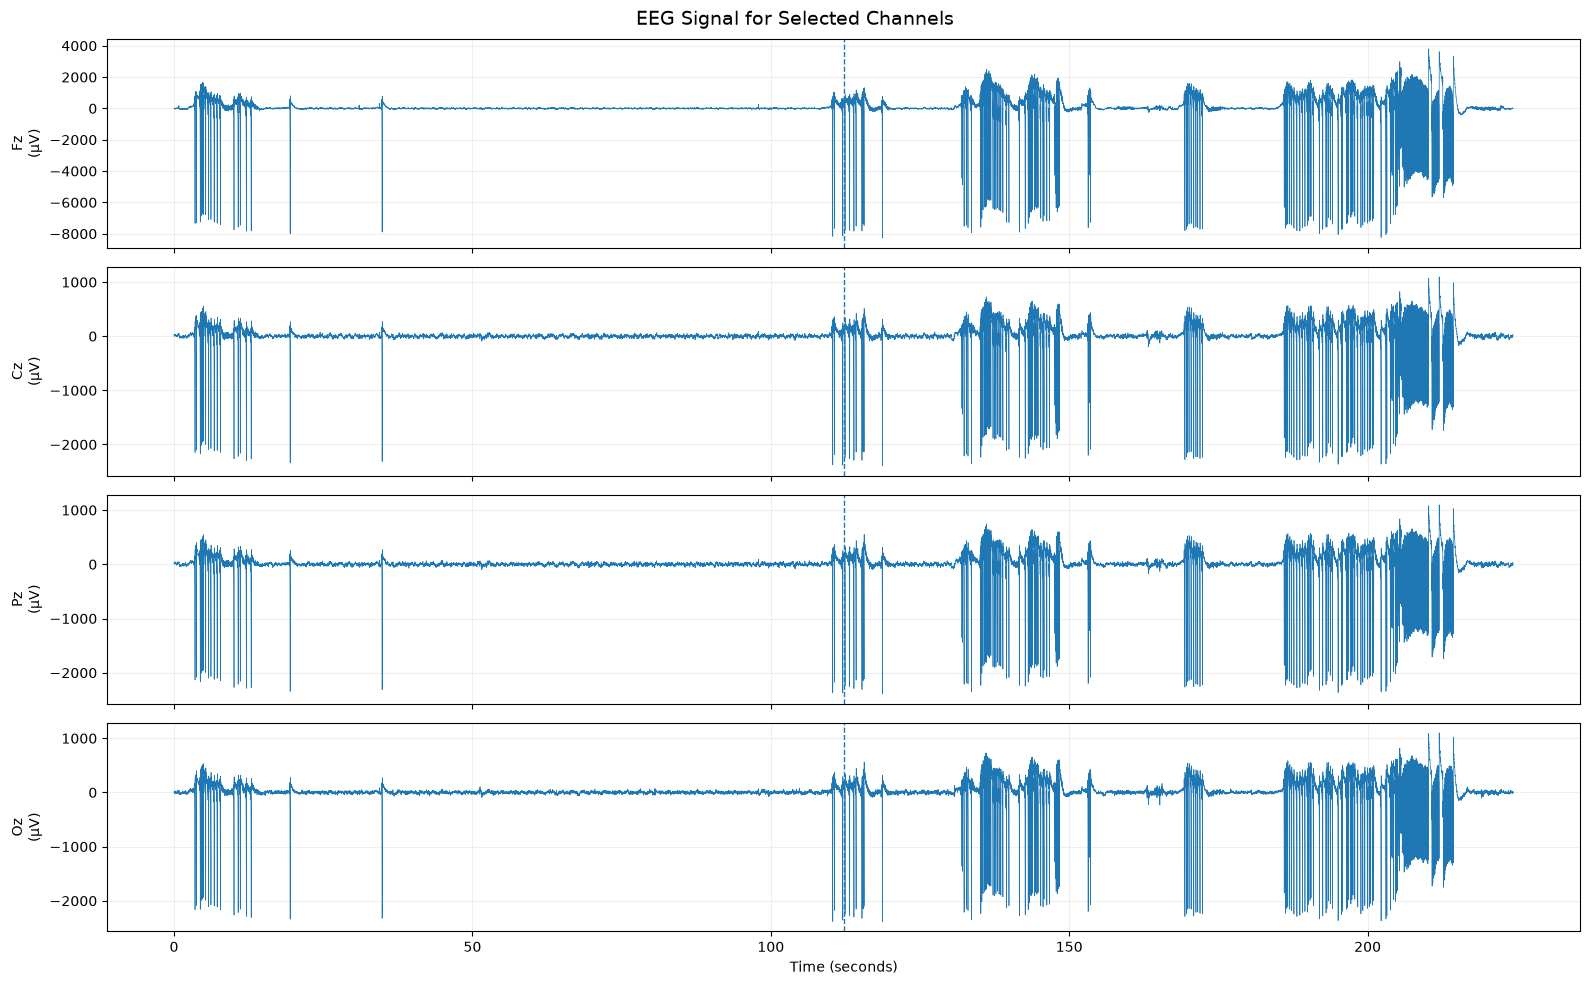

In [ ]:
channels_to_plot = ["Fz", "Cz", "Pz", "Oz"]

fig, axes = plt.subplots(
    len(channels_to_plot),
    1,
    figsize=(16, 10),
    sharex=True
)

for ax, ch in zip(axes, channels_to_plot):

    idx = raw2.ch_names.index(ch)

    ax.plot(
        raw2.times,
        data2[idx] * 1e6,
        linewidth=0.5
    )

    ax.axvline(
        raw2.times[-1]/2,
        linestyle="--",
        linewidth=1
    )

    ax.set_ylabel(f"{ch}\n(µV)")
    ax.grid(alpha=0.2)

axes[-1].set_xlabel("Time (seconds)")

fig.suptitle(
    "EEG Signal for Selected Channels",
    fontsize=14
)

plt.tight_layout()
plt.show()

In [13]:
# EEG preprocessing

raw_clean1 = raw1.copy()
raw_clean2 = raw2.copy()

# Band-pass filtering
raw_clean1.filter(
    l_freq=0.5,
    h_freq=50.0,
    fir_design="firwin"
)
raw_clean2.filter(
    l_freq=0.5,
    h_freq=50.0,
    fir_design="firwin"
)

# Notch filter for power-line interference
raw_clean1.notch_filter(freqs=50)
raw_clean2.notch_filter(freqs=50)

print("Preprocessing completed.")
print("High-pass filter : 0.5 Hz")
print("Low-pass filter  : 50 Hz")
print("Notch filter     : 50 Hz")

Filtering raw data in 1 contiguous segment
Setting up band-pass filter from 0.5 - 50 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 0.50
- Lower transition bandwidth: 0.50 Hz (-6 dB cutoff frequency: 0.25 Hz)
- Upper passband edge: 50.00 Hz
- Upper transition bandwidth: 12.50 Hz (-6 dB cutoff frequency: 56.25 Hz)
- Filter length: 1691 samples (6.605 s)

Filtering raw data in 1 contiguous segment
Setting up band-pass filter from 0.5 - 50 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 0.50
- Lower transition bandwidth: 0.50 Hz (-6 dB cutoff frequency: 0.25 Hz)
- Upper passband ed

Effective window size : 8.000 (s)
Plotting power spectral density (dB=True).


/var/folders/tj/grr23q4s2332hjy11pnwmt0c0000gn/T/ipykernel_31981/228808119.py:5: RuntimeWarning: Channel locations not available. Disabling spatial colors.
  ).plot(


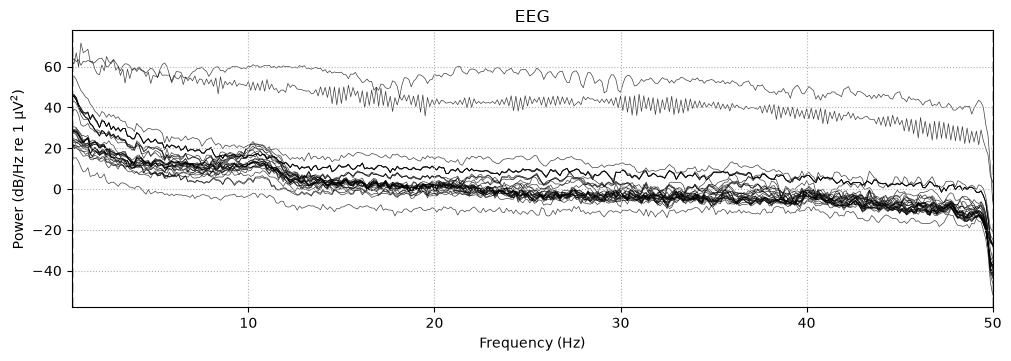

Effective window size : 8.000 (s)
Plotting power spectral density (dB=True).


/var/folders/tj/grr23q4s2332hjy11pnwmt0c0000gn/T/ipykernel_31981/228808119.py:14: RuntimeWarning: Channel locations not available. Disabling spatial colors.
  ).plot(


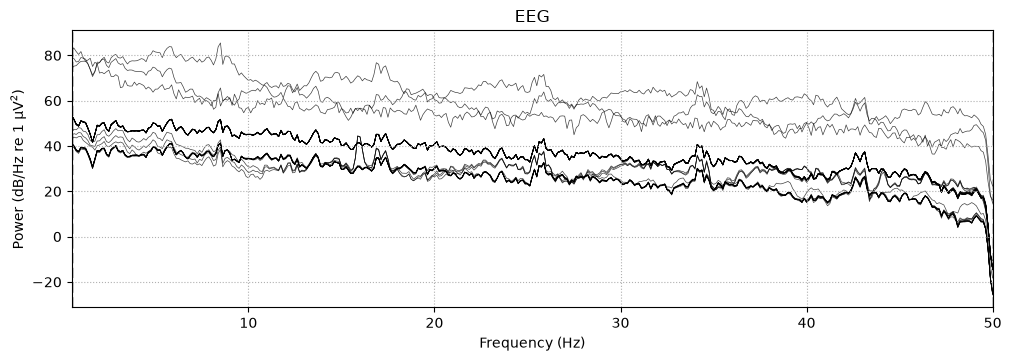

In [14]:
raw_clean1.compute_psd(
    fmin=0.5,
    fmax=50,
    n_fft=2048
).plot(
    average=False,
    picks="data"
)

raw_clean2.compute_psd(
    fmin=0.5,
    fmax=50,
    n_fft=2048
).plot(
    average=False,
    picks="data"
)

plt.show()

Effective window size : 8.000 (s)
Plotting power spectral density (dB=True).
Need more than one channel to make topography for eeg. Disabling interactivity.


/var/folders/tj/grr23q4s2332hjy11pnwmt0c0000gn/T/ipykernel_31981/278481060.py:7: RuntimeWarning: Channel locations not available. Disabling spatial colors.
  ).plot(


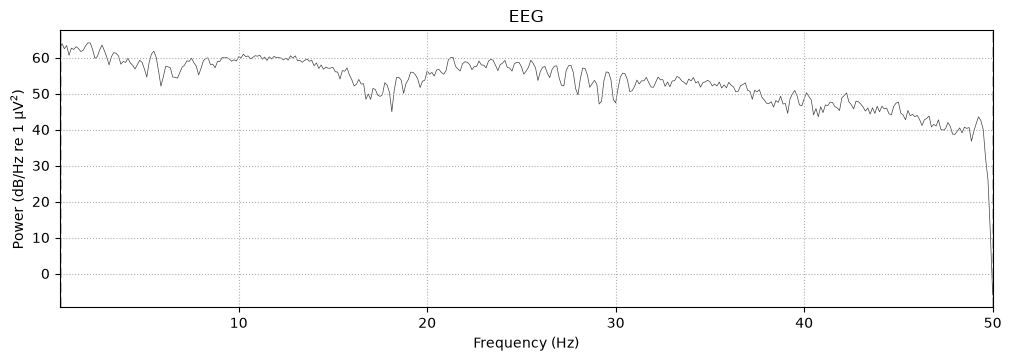

Effective window size : 8.000 (s)
Plotting power spectral density (dB=True).
Need more than one channel to make topography for eeg. Disabling interactivity.


/var/folders/tj/grr23q4s2332hjy11pnwmt0c0000gn/T/ipykernel_31981/278481060.py:16: RuntimeWarning: Channel locations not available. Disabling spatial colors.
  ).plot(


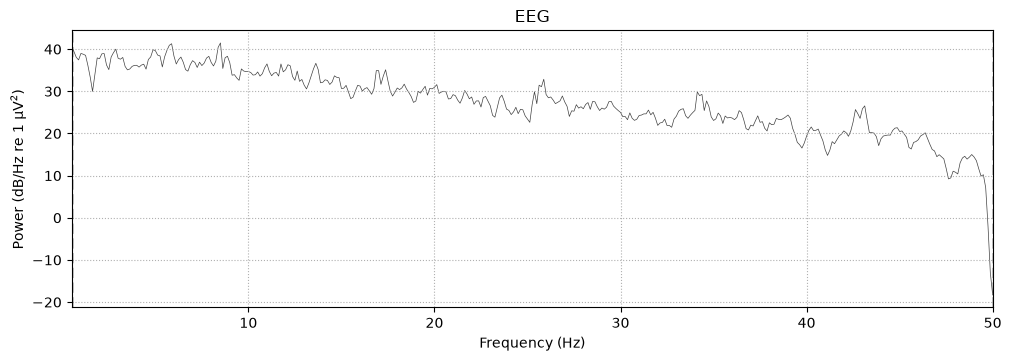

In [15]:
selected_channels = ["T8"]

raw_clean1.compute_psd(
    fmin=0.5,
    fmax=50,
    n_fft=2048
).plot(
    picks=selected_channels,
    average=False
)

raw_clean2.compute_psd(
    fmin=0.5,
    fmax=50,
    n_fft=2048
).plot(
    picks=selected_channels,
    average=False
)

plt.show()

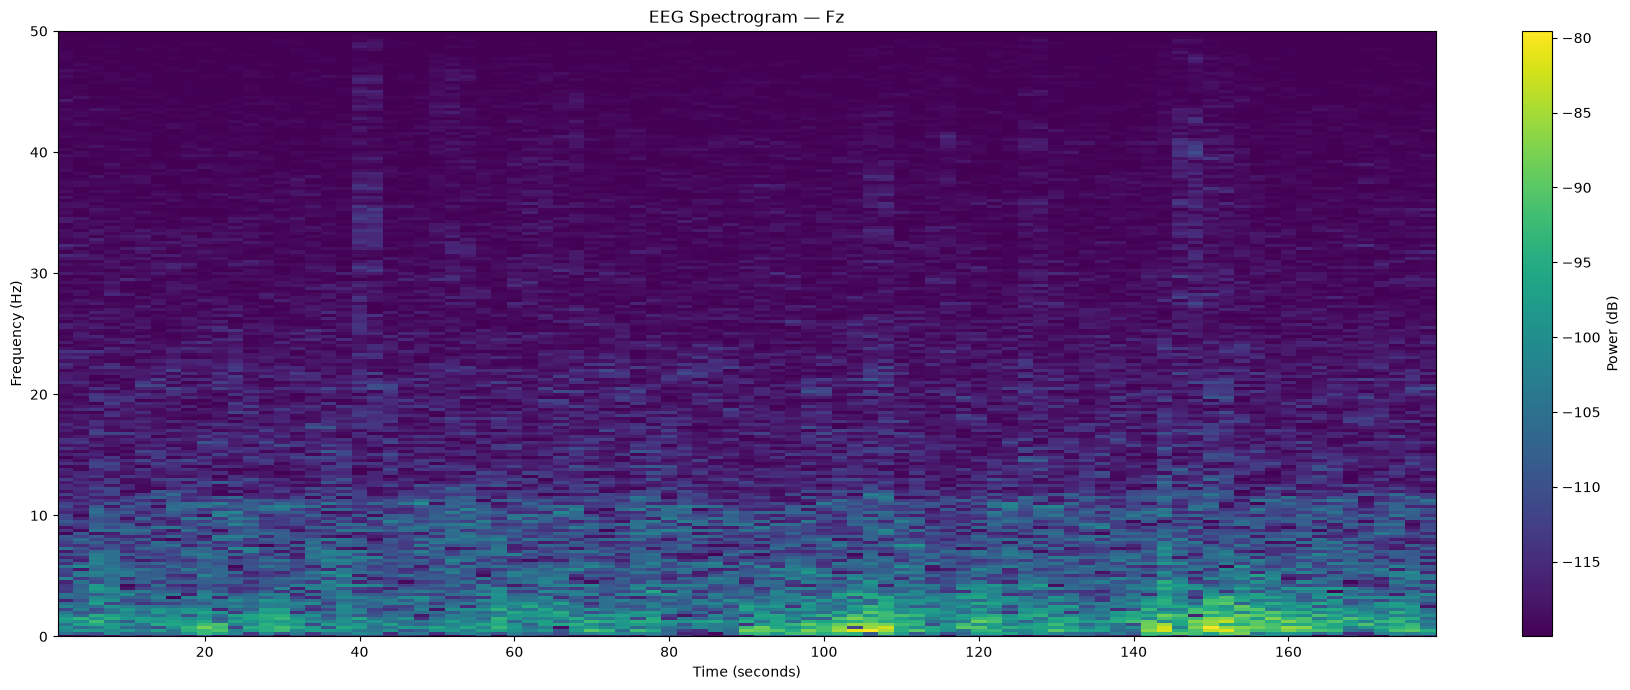

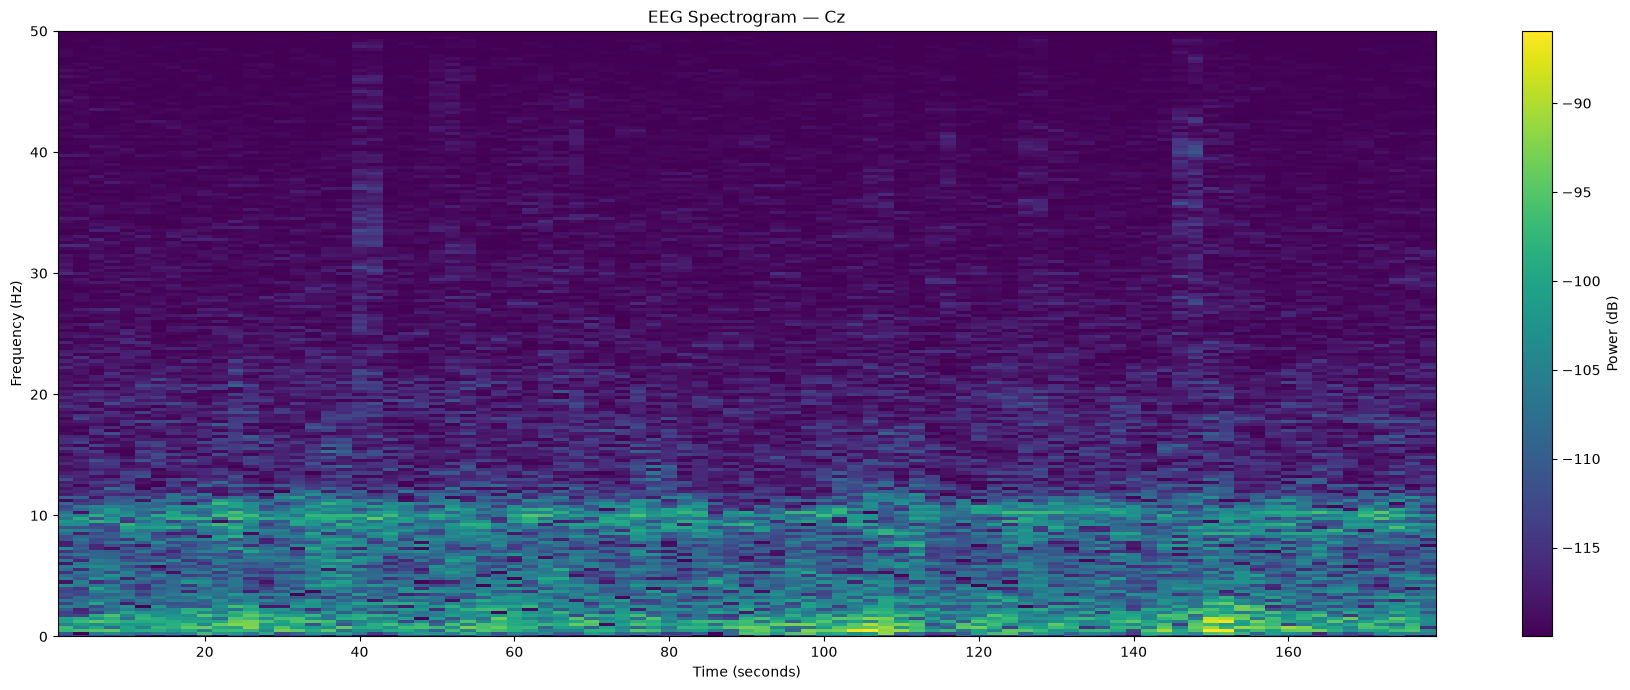

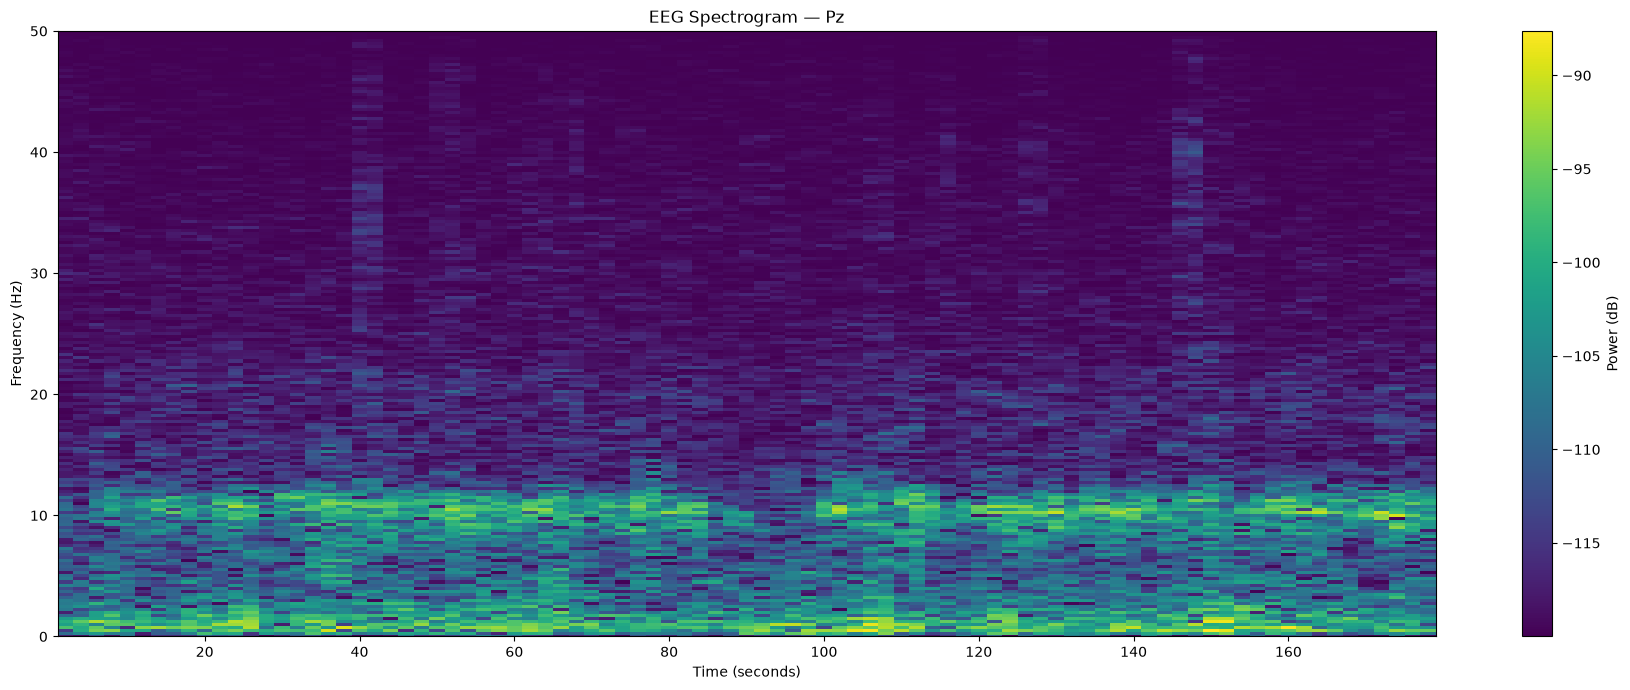

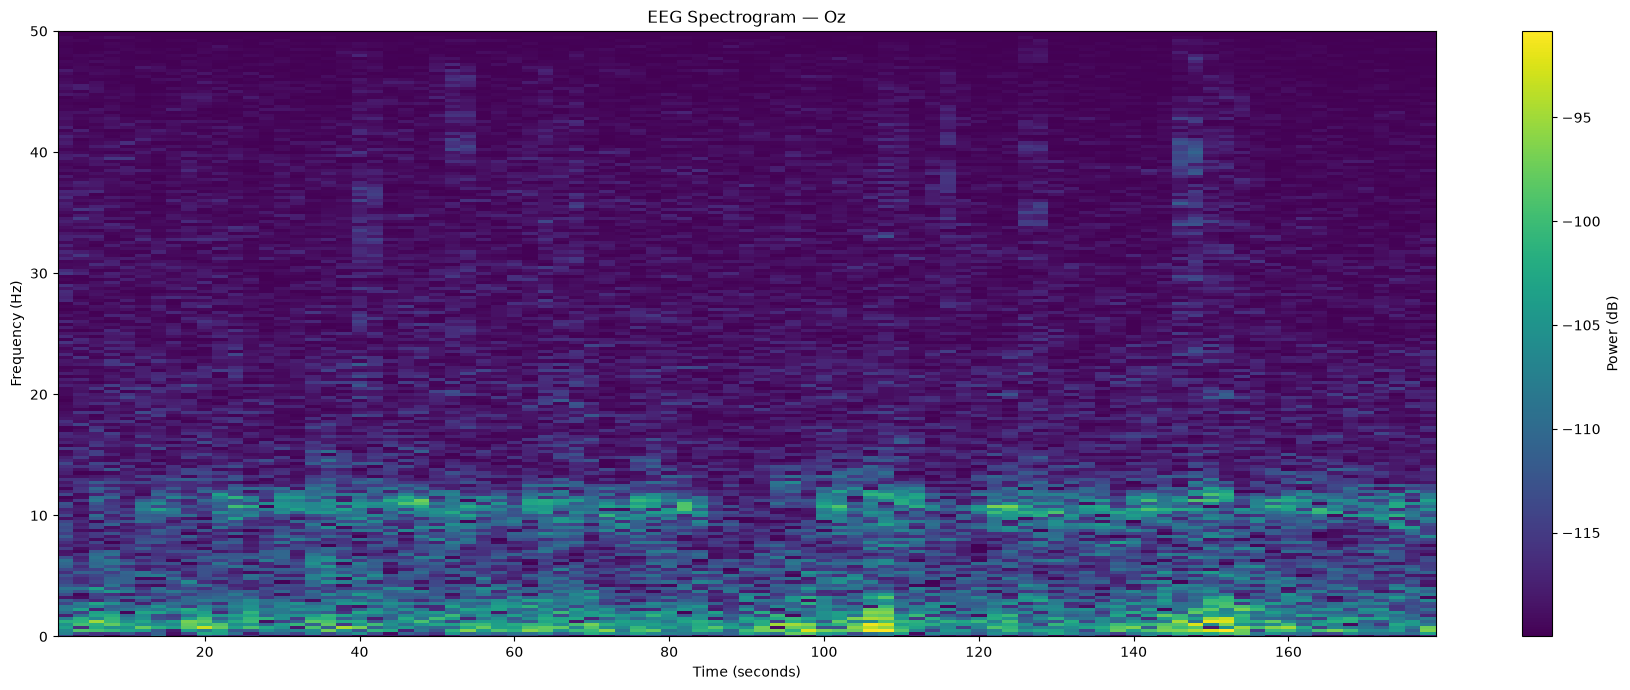

In [16]:
from scipy import signal

selected_channels = ["Fz", "Cz", "Pz", "Oz"]

for ch in selected_channels:
    idx = raw_clean1.ch_names.index(ch)

    eeg_signal = data1[idx]

    freqs, times_spec, Sxx = signal.spectrogram(
        eeg_signal,
        fs=raw_clean1.info["sfreq"],
        nperseg=1024,
        noverlap=512
    )

    mask = freqs <= 50

    plt.figure(figsize=(18, 7))

    plt.pcolormesh(
        times_spec,
        freqs[mask],
        10 * np.log10(Sxx[mask] + 1e-12),
        shading="auto"
    )

    plt.xlabel("Time (seconds)")
    plt.ylabel("Frequency (Hz)")
    plt.title(f"EEG Spectrogram — {ch}")

    plt.ylim(0, 50)

    plt.colorbar(label="Power (dB)")

    plt.tight_layout()
    plt.show()

In [17]:
for ch in ["Fz", "Cz", "Pz", "Oz"]:

    idx = raw_clean1.ch_names.index(ch)

    signal_uv = data1[idx] * 1e6

    max_idx = np.argmax(np.abs(signal_uv))

    print(
        f"{ch}: "
        f"time={raw_clean1.times[max_idx]:.3f}s, "
        f"value={signal_uv[max_idx]:.2f} µV"
    )

Fz: time=143.875s, value=-322.54 µV
Cz: time=25.457s, value=-130.93 µV
Pz: time=25.453s, value=-140.64 µV
Oz: time=106.766s, value=95.07 µV


Using matplotlib as 2D backend.


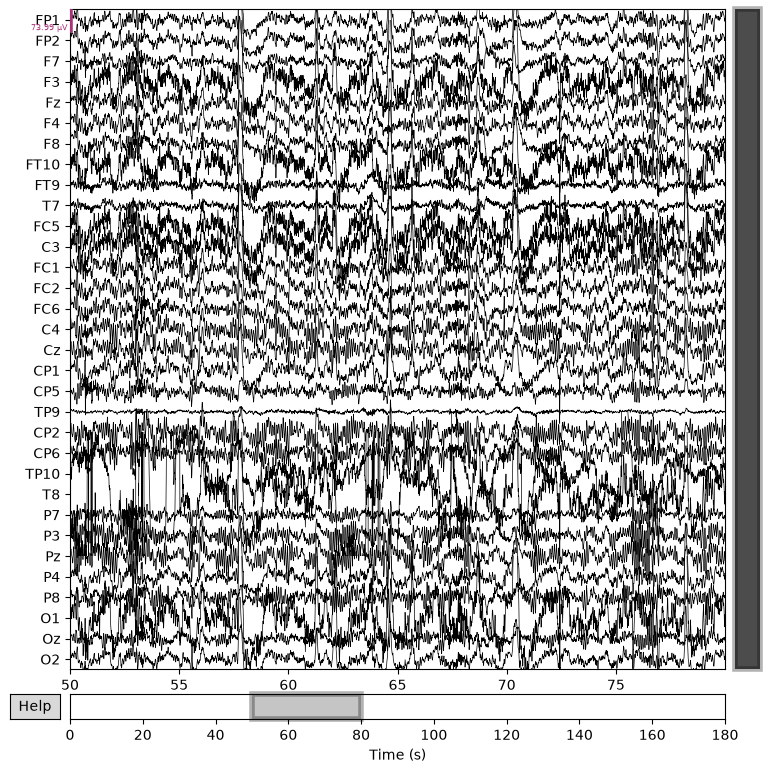

In [18]:
fig = raw_clean1.plot(
    start=50,
    duration=30,
    n_channels=32,
    scalings="auto"
)

In [19]:
print("========== ANNOTATIONS ==========")
print(raw1.annotations)

events, event_id = mne.events_from_annotations(raw1)

print("\nEvents shape:", events.shape)
print("Event IDs:", event_id)

if len(events) > 0:
    print("\nFirst events:")
    print(events[:20])
else:
    print("No annotation-based events found.")

========== ANNOTATIONS ==========
<Annotations | 0 segments>

Events shape: (0, 3)
Event IDs: {}
No annotation-based events found.
